In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [2]:
df=pd.read_csv('Adult Census Income.csv')
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


| Column           | Description                                                                    |
| ---------------- | ------------------------------------------------------------------------------ |
| `age`            | Age of the person in years.                                                    |
| `workclass`      | Type of employer or employment sector, such as Private or Self-emp.            |
| `fnlwgt`         | Statistical sampling weight used to represent people in census data.           |
| `education`      | Highest educational level attained, such as HS-grad or Bachelors.              |
| `education.num`  | Numerical representation of the educational level.                             |
| `marital.status` | Marital status, such as Married, Divorced, or Widowed.                         |
| `occupation`     | Type of job or profession, such as Exec-managerial or Prof-specialty.          |
| `relationship`   | Relationship status within the household, such as Husband, Wife, or Own-child. |
| `race`           | Racial category as recorded in the dataset, such as White or Black.            |
| `sex`            | Sex recorded in the dataset, such as Male or Female.                           |
| `capital.gain`   | Financial gains from capital assets, such as profits from selling assets.      |
| `capital.loss`   | Financial losses from capital assets.                                          |
| `hours.per.week` | Number of hours the person works per week.                                     |
| `native.country` | Country of origin recorded in the dataset.                                     |
| `income`         | Target variable indicating whether annual income is `<=50K` or `>50K`.         |

In [3]:
df.shape

(32561, 15)

In [4]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [6]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [7]:
df.replace('?',np.nan,inplace=True)

In [8]:
df.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

In [9]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
for col in ['workclass','occupation','native.country']:
    df[[col]] = imputer.fit_transform(df[[col]])


In [10]:
df.duplicated().sum()

np.int64(24)

In [11]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True,inplace=True)

In [12]:
df.drop(columns=['education'],axis=1,inplace=True)

In [13]:
#sns.countplot(x='income', data=df)

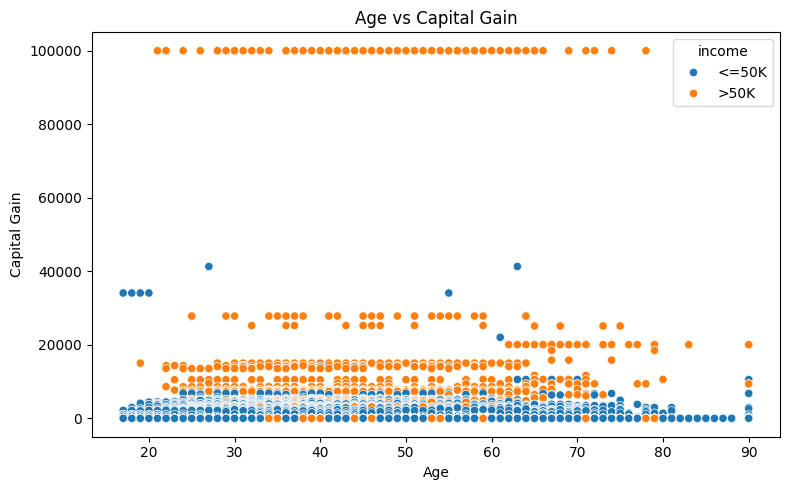

In [14]:
import seaborn as sns
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="capital.gain",
    hue="income"
)

plt.title("Age vs Capital Gain")
plt.xlabel("Age")
plt.ylabel("Capital Gain")

plt.tight_layout()
plt.show()

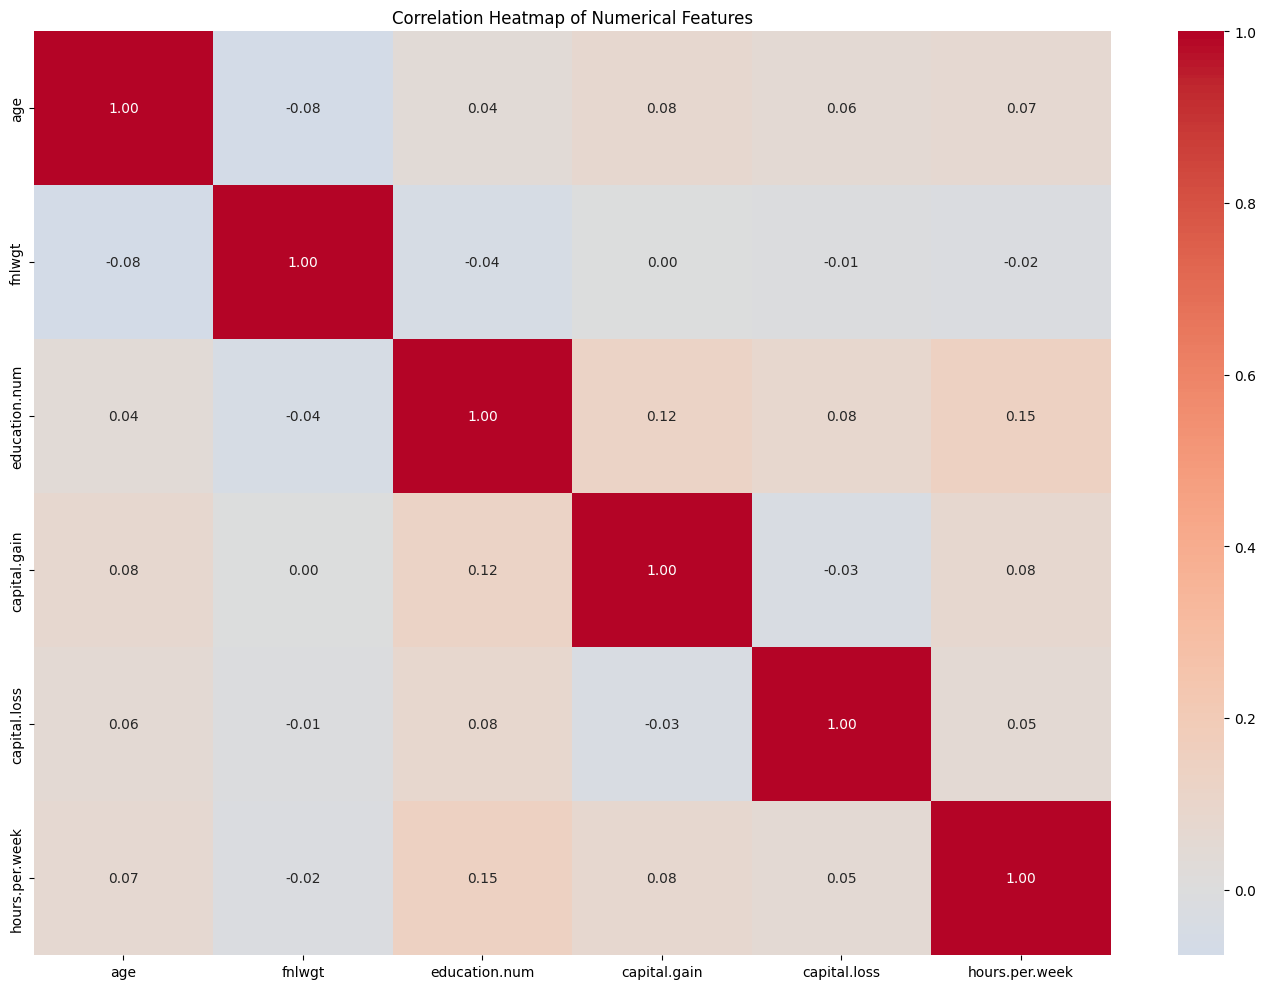

In [15]:

numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [16]:
df.select_dtypes(include=['object']).nunique()

workclass          8
marital.status     7
occupation        14
relationship       6
race               5
sex                2
native.country    41
income             2
dtype: int64

In [17]:

for col in df.select_dtypes(include=['object']).columns:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in workclass:
['Private' 'State-gov' 'Federal-gov' 'Self-emp-not-inc' 'Self-emp-inc'
 'Local-gov' 'Without-pay' 'Never-worked']

Unique values in marital.status:
['Widowed' 'Divorced' 'Separated' 'Never-married' 'Married-civ-spouse'
 'Married-spouse-absent' 'Married-AF-spouse']

Unique values in occupation:
['Prof-specialty' 'Exec-managerial' 'Machine-op-inspct' 'Other-service'
 'Adm-clerical' 'Craft-repair' 'Transport-moving' 'Handlers-cleaners'
 'Sales' 'Farming-fishing' 'Tech-support' 'Protective-serv' 'Armed-Forces'
 'Priv-house-serv']

Unique values in relationship:
['Not-in-family' 'Unmarried' 'Own-child' 'Other-relative' 'Husband' 'Wife']

Unique values in race:
['White' 'Black' 'Asian-Pac-Islander' 'Other' 'Amer-Indian-Eskimo']

Unique values in sex:
['Female' 'Male']

Unique values in native.country:
['United-States' 'Mexico' 'Greece' 'Vietnam' 'China' 'Taiwan' 'India'
 'Philippines' 'Trinadad&Tobago' 'Canada' 'South' 'Holand-Netherlands'
 'Puerto-Rico' 'Poland'

In [18]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['sex'] = le.fit_transform(df['sex'])
df['income'] = le.fit_transform(df['income'])



In [19]:
from sklearn.preprocessing import OneHotEncoder
onehot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

temp = onehot.fit_transform(df[['race','relationship','marital.status','workclass']])
df = pd.concat([df,temp],axis=1)
df.drop(['race','relationship','marital.status','workclass'],axis=1,inplace=True)

In [20]:
X=df.drop('income', axis=1)
y=df['income']

In [21]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train = ",x_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",x_test.shape ," y_test  = ", y_test.shape)

X_train =  (26029, 31)  y_train =  (26029,)
X_test  =  (6508, 31)  y_test  =  (6508,)


In [22]:
import category_encoders as ce
target_enc = ce.TargetEncoder(
    cols=['occupation','native.country'],
    smoothing=5
)

x_train[['occupation_new','native.country_new']] = target_enc.fit_transform(
    x_train[['occupation','native.country']],
    y_train
)
x_test[['occupation_new','native.country_new']] = target_enc.transform(
    x_test[['occupation','native.country']]
)


In [23]:
x_train.drop(columns=['occupation','native.country'], inplace=True)
x_test.drop(columns=['occupation','native.country'], inplace=True)

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(x_train)
X_test = scaler.transform(x_test)

In [25]:
results=[]
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
model_lr = LogisticRegression(class_weight='balanced',max_iter=1000)
model_lr.fit(X_train, y_train)
y_pred = model_lr.predict(X_test)

results.append({
    'Method': "Class Weight Balanced LogisticRegression",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [26]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

for name, y_pred in [('Logistic', y_pred)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred))
   print(confusion_matrix(y_test, y_pred))
   print(classification_report(y_test, y_pred))
   print()

Logistic
Accuracy: 0.8022433927473879
[[3926 1014]
 [ 273 1295]]
              precision    recall  f1-score   support

           0       0.93      0.79      0.86      4940
           1       0.56      0.83      0.67      1568

    accuracy                           0.80      6508
   macro avg       0.75      0.81      0.76      6508
weighted avg       0.84      0.80      0.81      6508




In [27]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Class Weight Balanced LogisticRegression,0.802243,0.560849,0.825893,0.668042


In [28]:
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

model_knn = KNeighborsClassifier(n_neighbors=5,metric='minkowski',p=1) 
model_knn.fit(X_train,y_train) 
y_pred = model_knn.predict(X_test)
y_pred_train = model_knn.predict(X_train) 
y_pred_test = model_knn.predict (X_test)
results.append({
    'Method': "KNeighborsClassifier",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})


In [29]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

for name, y_pred in [('model_knn', y_pred)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred))
   print(confusion_matrix(y_test, y_pred))
   print(classification_report(y_test, y_pred))
   print()


model_knn
Accuracy: 0.8325138291333744
[[4503  437]
 [ 653  915]]
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      4940
           1       0.68      0.58      0.63      1568

    accuracy                           0.83      6508
   macro avg       0.78      0.75      0.76      6508
weighted avg       0.83      0.83      0.83      6508




In [30]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Class Weight Balanced LogisticRegression,0.802243,0.560849,0.825893,0.668042
KNeighborsClassifier,0.832514,0.676775,0.583546,0.626712


In [31]:
from sklearn.naive_bayes import GaussianNB
model_nb =GaussianNB()
model_nb.fit(X_train,y_train) 
y_pred = model_nb.predict(X_test)
y_pred_train = model_nb.predict(X_train) 
y_pred_test = model_nb.predict (X_test)
results.append({
    'Method': "GaussianNB",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})


In [32]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

for name, y_pred in [('GaussianNB', y_pred)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred))
   print(confusion_matrix(y_test, y_pred))
   print(classification_report(y_test, y_pred))
   print()


GaussianNB
Accuracy: 0.5207437000614629
[[1884 3056]
 [  63 1505]]
              precision    recall  f1-score   support

           0       0.97      0.38      0.55      4940
           1       0.33      0.96      0.49      1568

    accuracy                           0.52      6508
   macro avg       0.65      0.67      0.52      6508
weighted avg       0.81      0.52      0.53      6508




In [33]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Class Weight Balanced LogisticRegression,0.802243,0.560849,0.825893,0.668042
KNeighborsClassifier,0.832514,0.676775,0.583546,0.626712
GaussianNB,0.520744,0.329971,0.959821,0.491108


In [34]:
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [35]:
model = SVC(C=0.1, kernel='linear',gamma='auto')

model.fit(X_train,y_train)

SVC(C=0.1, gamma='auto', kernel='linear')

In [36]:
y_pred = model.predict(X_test)

In [37]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.848340503995083
              precision    recall  f1-score   support

           0       0.87      0.94      0.90      4940
           1       0.74      0.57      0.64      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.75      0.77      6508
weighted avg       0.84      0.85      0.84      6508



In [38]:
from sklearn.tree import DecisionTreeClassifier,plot_tree


In [39]:
model = DecisionTreeClassifier(

        criterion='gini',
        random_state=100,
        max_depth=10, 
        min_samples_split=10,
        min_samples_leaf=5,
        min_impurity_decrease=0.01,

        ccp_alpha=0.01
    )



In [40]:
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

Acc_Train = accuracy_score(y_train, y_pred_train)
Acc_Test  = accuracy_score(y_test, y_pred_test)

print(
    Acc_Train, 
    Acc_Test,  
)

0.8442506435130047 0.8415795943454211


Decision Tree - Plotting the tree


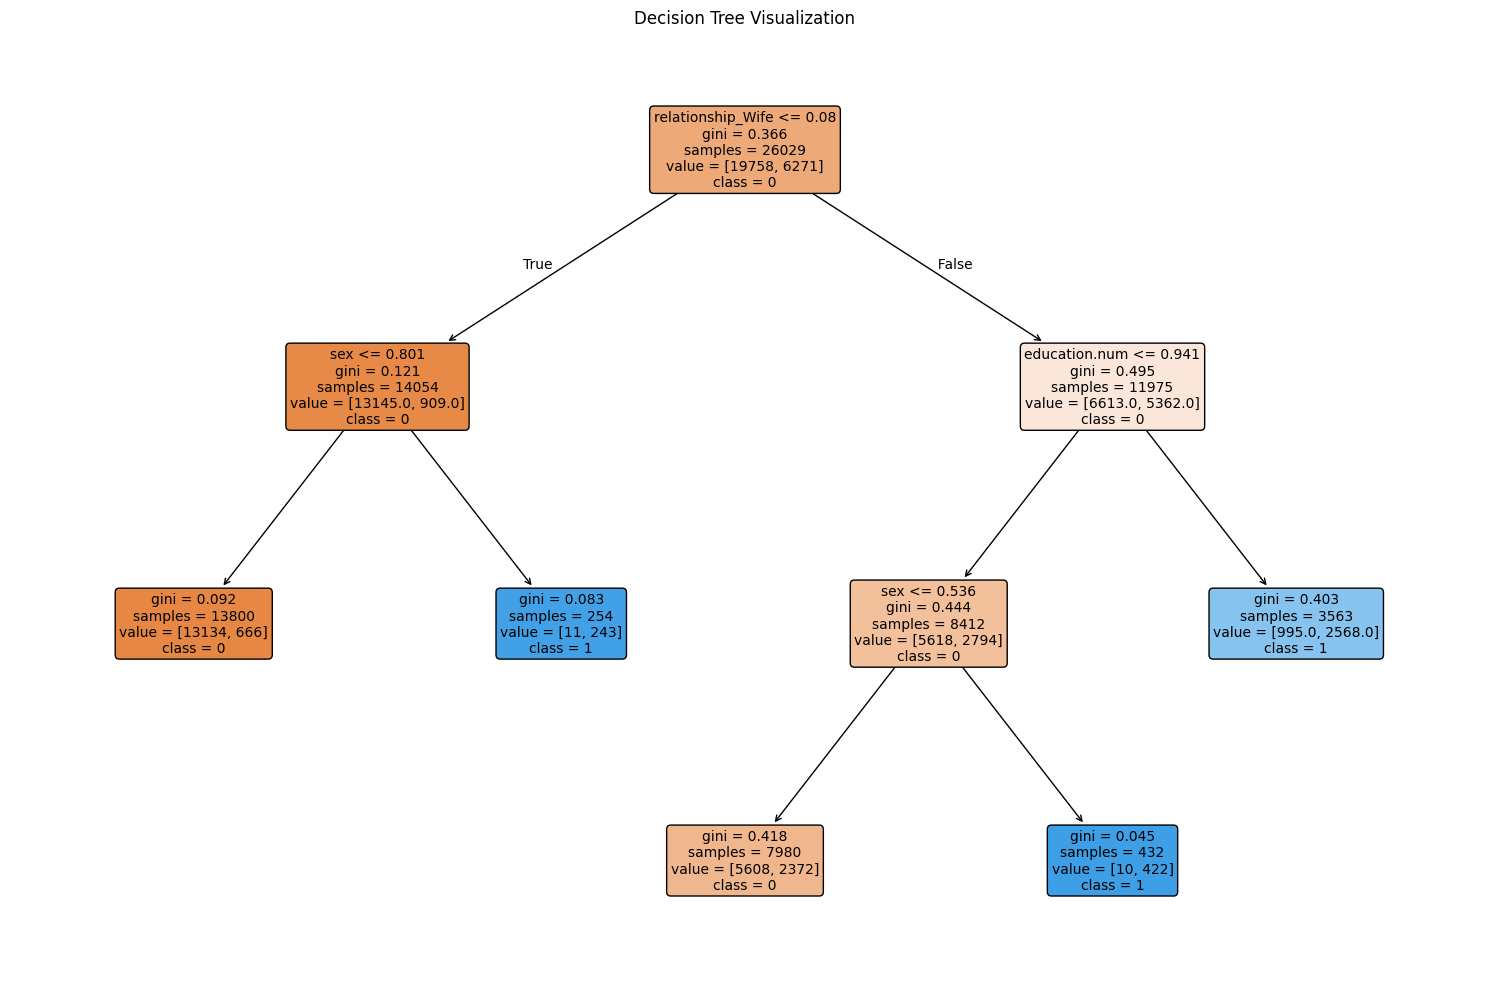

In [41]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [42]:

rf = DecisionTreeClassifier( random_state=42)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_,index=X.columns)

importances = importances.sort_values(ascending=False)

selected_columns = importances.sort_values(ascending=False).index[:5]
print("DecisionTree Selected Features:",selected_columns.tolist())
selected_features = importances.nlargest(5)
print("Decision Tree Selected Features:", selected_features.tolist())

DecisionTree Selected Features: ['relationship_Wife', 'fnlwgt', 'education.num', 'age', 'sex']
Decision Tree Selected Features: [0.1993382816989624, 0.19527099338421725, 0.1280138802901989, 0.11175941844879746, 0.10644058644670343]


In [43]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[4605  335]
 [ 647  921]]


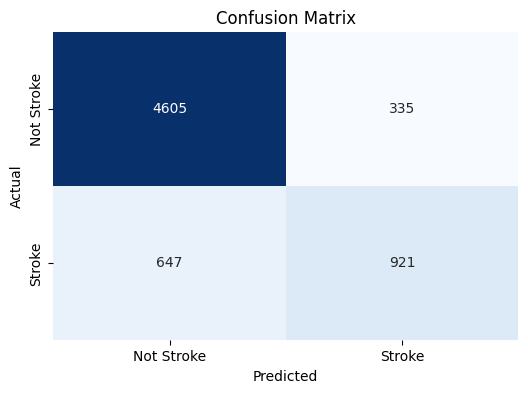


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.93      0.90      4940
      Stroke       0.73      0.59      0.65      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.76      0.78      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.8989431855738247


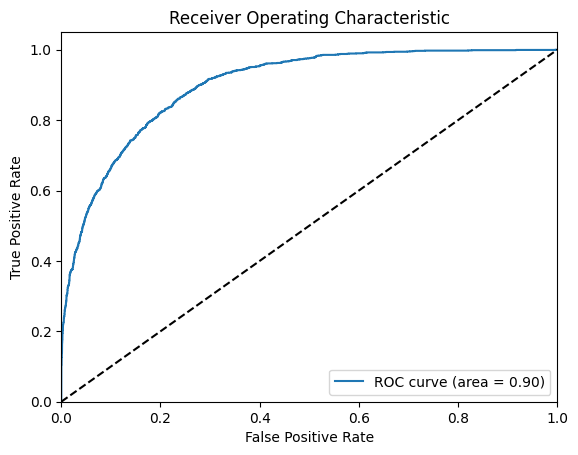

PR AUC: 0.760178842638971


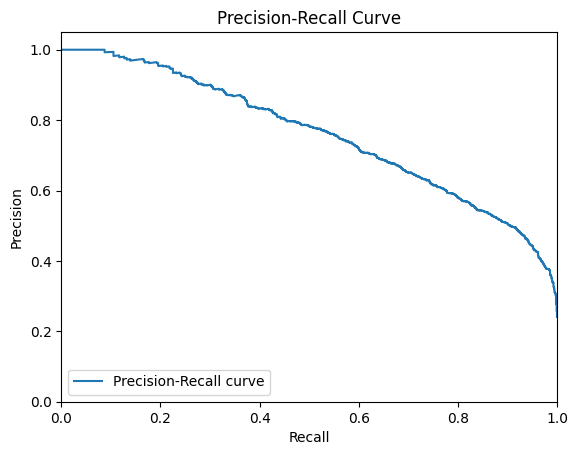

  8%|▊         | 1/13 [00:01<00:15,  1.26s/it]


Confusion Matrix:
 [[4481  459]
 [ 660  908]]


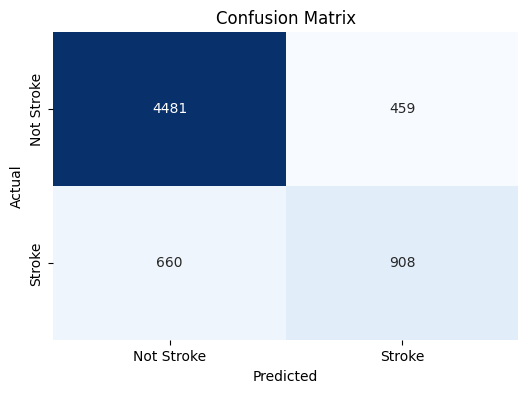


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.91      0.89      4940
      Stroke       0.66      0.58      0.62      1568

    accuracy                           0.83      6508
   macro avg       0.77      0.74      0.75      6508
weighted avg       0.82      0.83      0.82      6508

ROC-AUC: 0.848048133727175


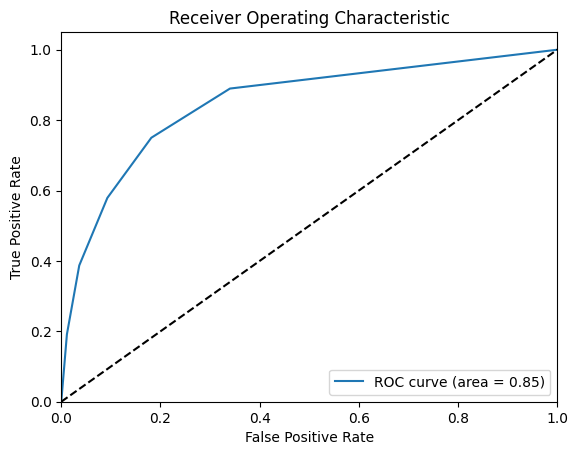

PR AUC: 0.6268459848460008


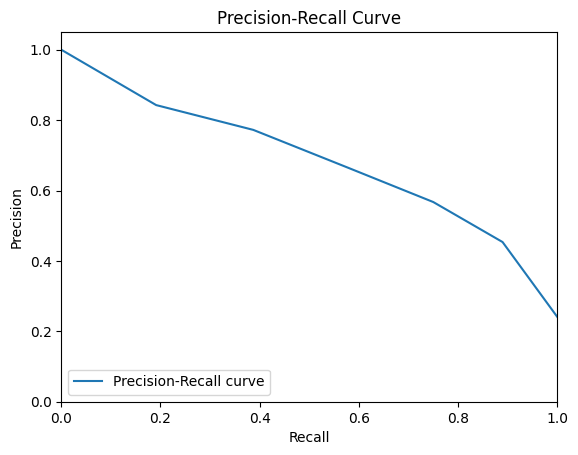

 15%|█▌        | 2/13 [00:14<01:28,  8.09s/it]


Confusion Matrix:
 [[4648  292]
 [ 694  874]]


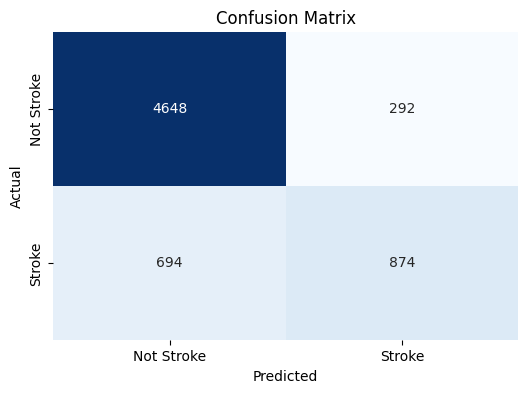


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.94      0.90      4940
      Stroke       0.75      0.56      0.64      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.75      0.77      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.8875121354209701


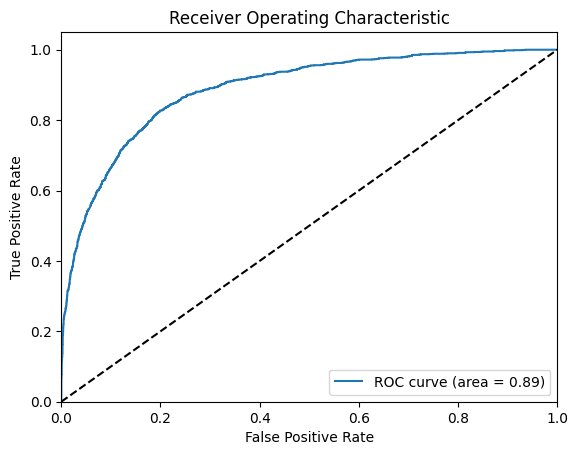

PR AUC: 0.7512561393089133


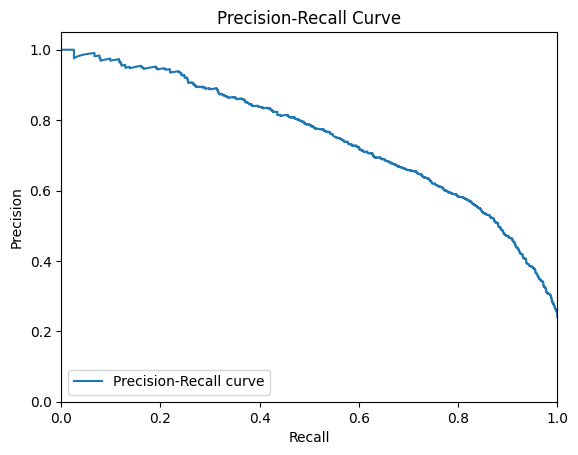

 23%|██▎       | 3/13 [05:37<25:19, 151.97s/it]


Confusion Matrix:
 [[4354  586]
 [ 615  953]]


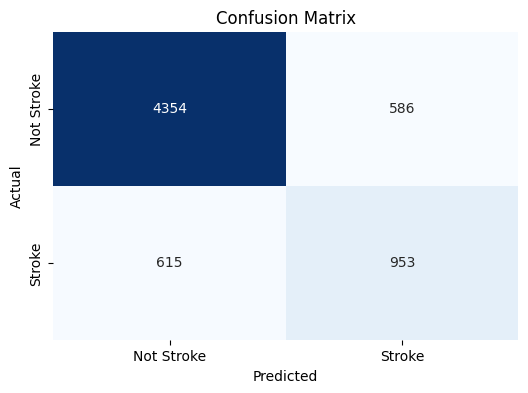


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.88      0.88      4940
      Stroke       0.62      0.61      0.61      1568

    accuracy                           0.82      6508
   macro avg       0.75      0.74      0.75      6508
weighted avg       0.81      0.82      0.81      6508

ROC-AUC: 0.7445785652317607


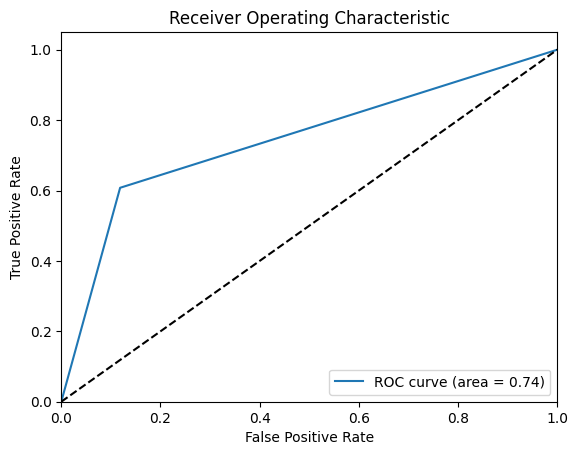

PR AUC: 0.4708570530216397


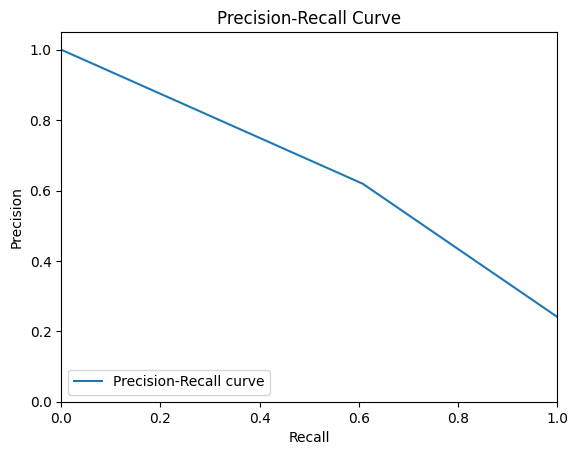

 31%|███       | 4/13 [05:37<13:50, 92.23s/it] 


Confusion Matrix:
 [[1884 3056]
 [  63 1505]]


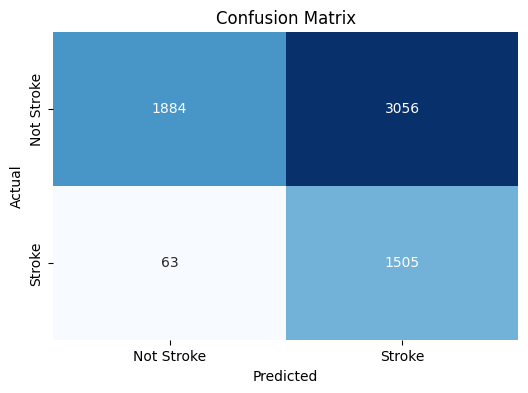


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.38      0.55      4940
      Stroke       0.33      0.96      0.49      1568

    accuracy                           0.52      6508
   macro avg       0.65      0.67      0.52      6508
weighted avg       0.81      0.52      0.53      6508

ROC-AUC: 0.8547821304635213


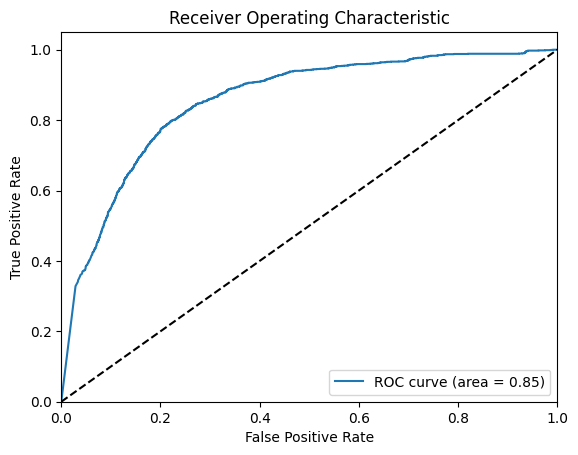

PR AUC: 0.640278220129537


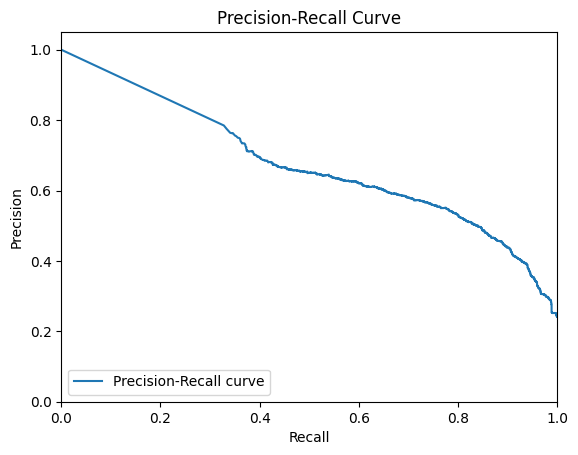

 38%|███▊      | 5/13 [05:38<07:53, 59.14s/it]


Confusion Matrix:
 [[4601  339]
 [ 607  961]]


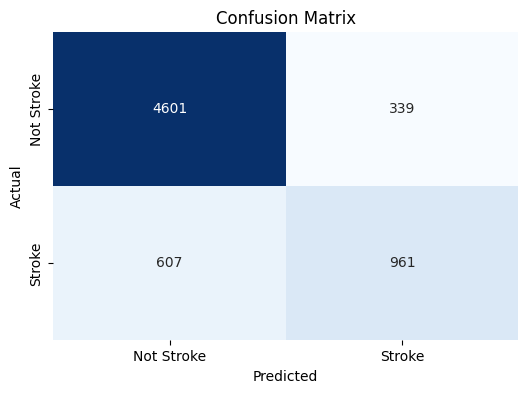


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.93      0.91      4940
      Stroke       0.74      0.61      0.67      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.77      0.79      6508
weighted avg       0.85      0.85      0.85      6508

ROC-AUC: 0.8984278820333802


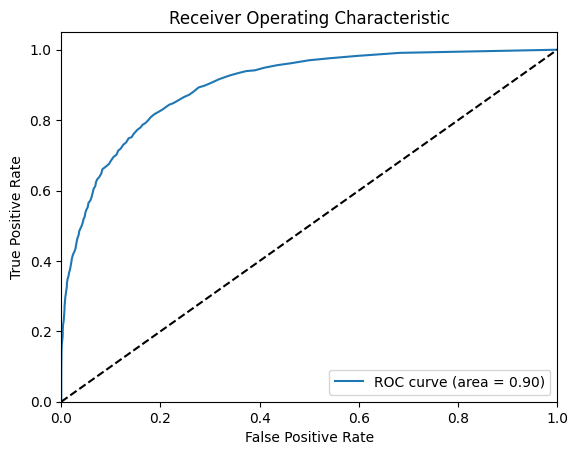

PR AUC: 0.7667493026822151


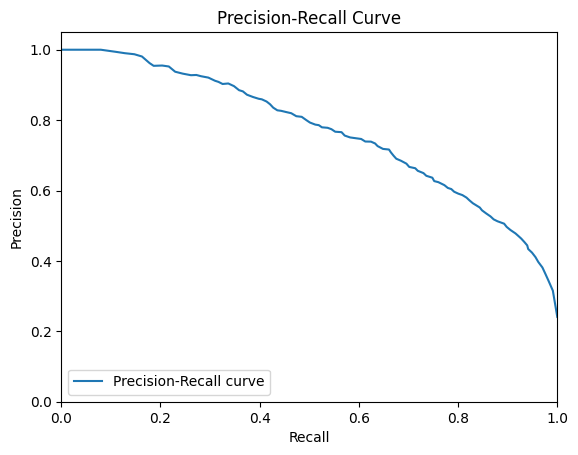

 46%|████▌     | 6/13 [05:43<04:45, 40.73s/it]


Confusion Matrix:
 [[4528  412]
 [ 631  937]]


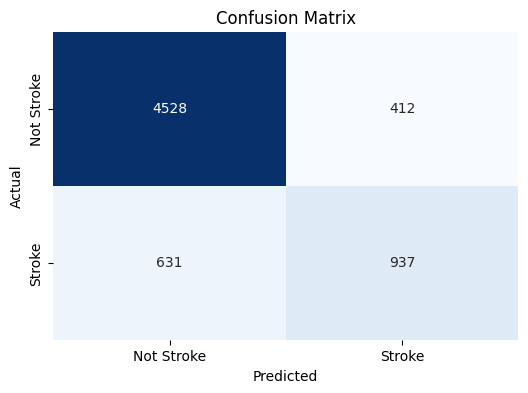


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.92      0.90      4940
      Stroke       0.69      0.60      0.64      1568

    accuracy                           0.84      6508
   macro avg       0.79      0.76      0.77      6508
weighted avg       0.83      0.84      0.84      6508

ROC-AUC: 0.8810001265182187


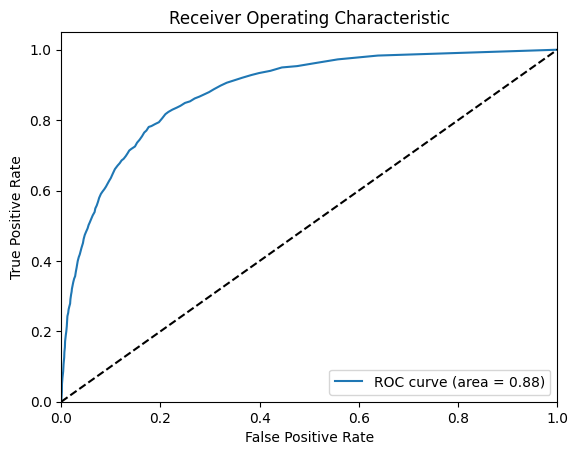

PR AUC: 0.7043324136857501


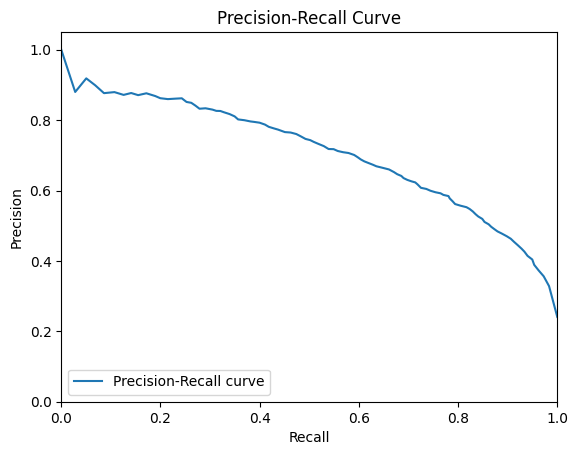

 54%|█████▍    | 7/13 [05:48<02:53, 29.00s/it]


Confusion Matrix:
 [[4622  318]
 [ 662  906]]


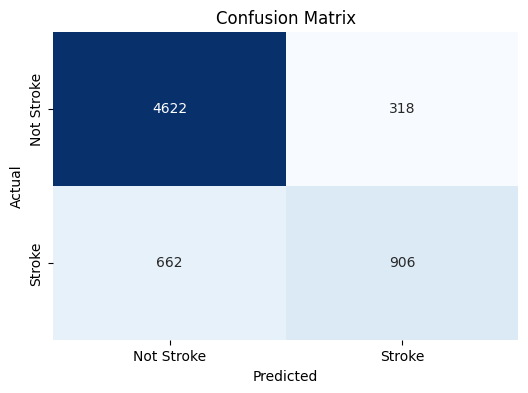


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.94      0.90      4940
      Stroke       0.74      0.58      0.65      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.76      0.78      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.8990678963893249


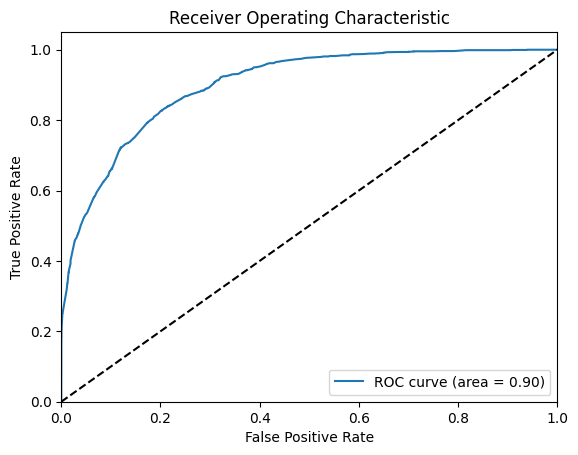

PR AUC: 0.7666335441867068


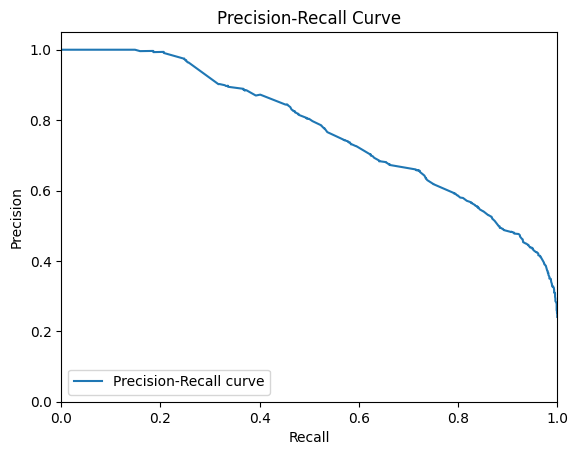

 62%|██████▏   | 8/13 [05:50<01:41, 20.35s/it]


Confusion Matrix:
 [[4661  279]
 [ 631  937]]


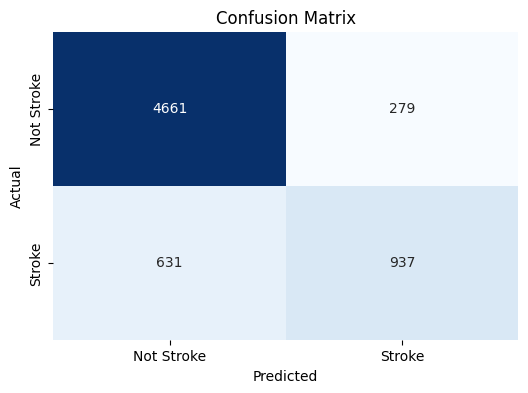


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.94      0.91      4940
      Stroke       0.77      0.60      0.67      1568

    accuracy                           0.86      6508
   macro avg       0.83      0.77      0.79      6508
weighted avg       0.85      0.86      0.85      6508

ROC-AUC: 0.9145954902710072


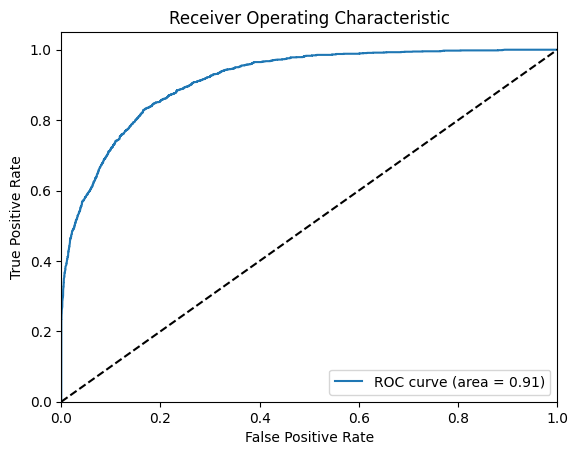

PR AUC: 0.8074534835306891


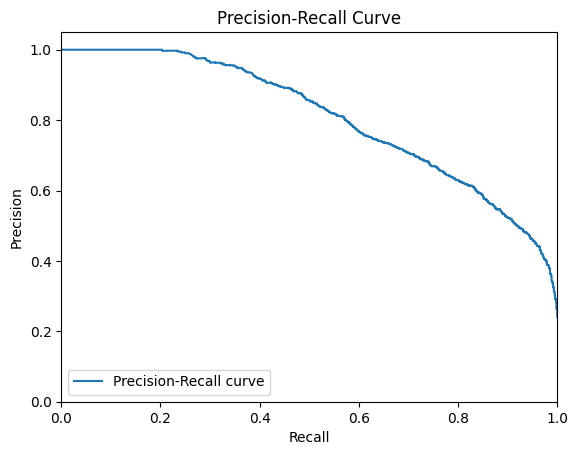

 69%|██████▉   | 9/13 [05:54<01:01, 15.37s/it]


Confusion Matrix:
 [[4657  283]
 [ 582  986]]


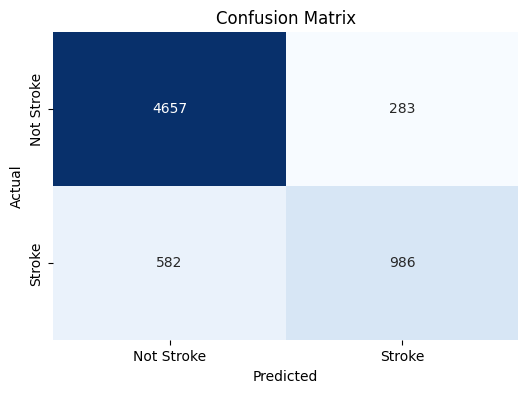


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.92      4940
      Stroke       0.78      0.63      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.81      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.919759886495084


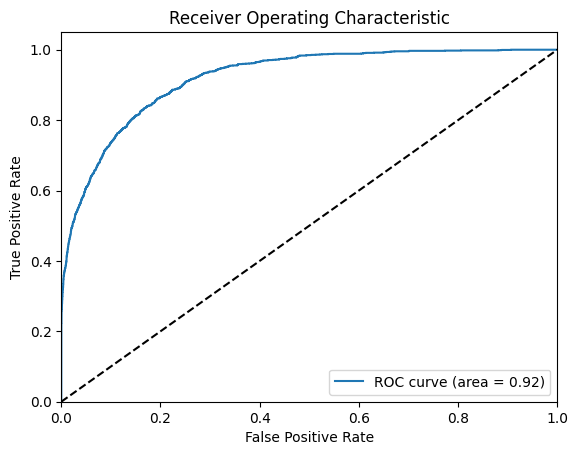

PR AUC: 0.8182197251812925


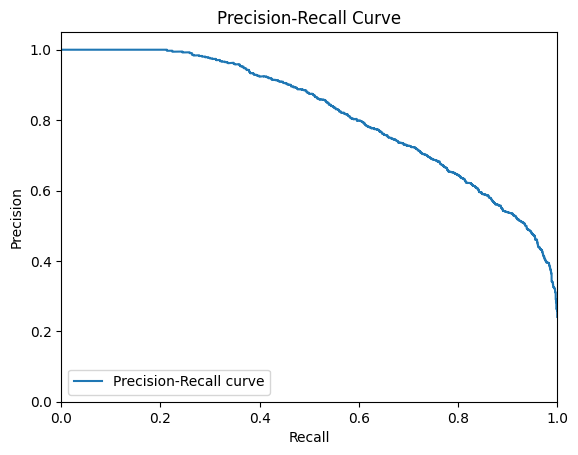

 77%|███████▋  | 10/13 [05:56<00:33, 11.25s/it]c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [08:44:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4624  316]
 [ 572  996]]


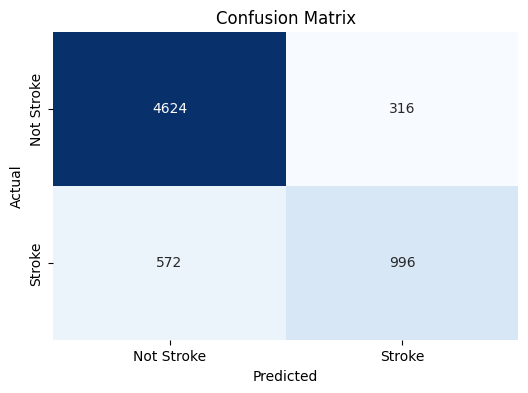


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4940
      Stroke       0.76      0.64      0.69      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.79      0.80      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.9187920221226141


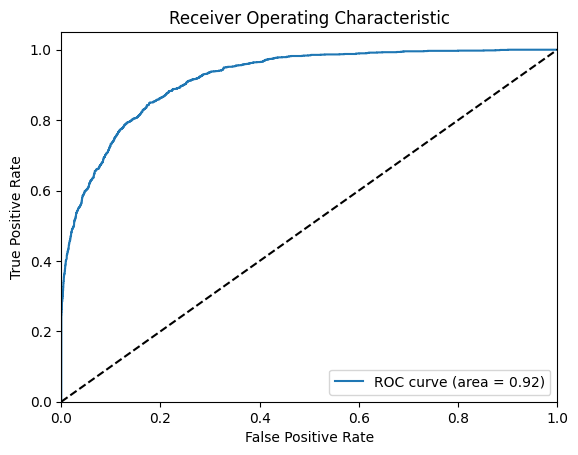

PR AUC: 0.8155170746669449


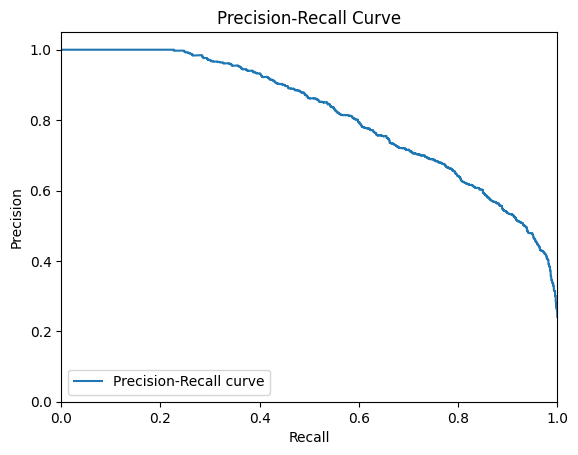

 85%|████████▍ | 11/13 [05:57<00:16,  8.12s/it]


Confusion Matrix:
 [[4641  299]
 [ 566 1002]]


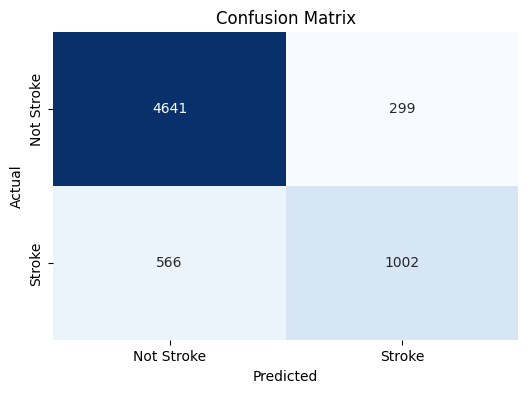


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4940
      Stroke       0.77      0.64      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.81      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.921558317152772


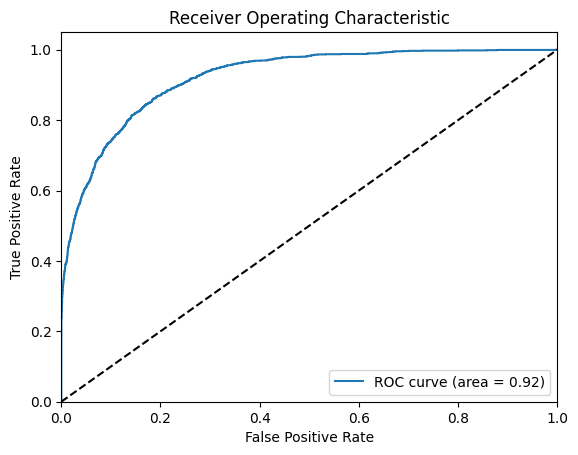

PR AUC: 0.8205996509847441


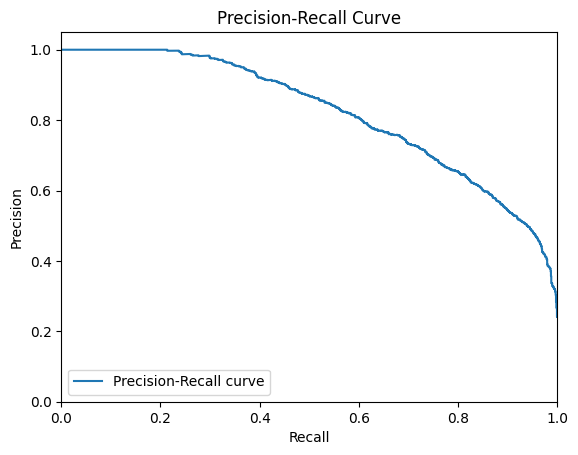

 92%|█████████▏| 12/13 [06:09<00:09,  9.42s/it]

[LightGBM] [Info] Number of positive: 6271, number of negative: 19758
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005294 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 697
[LightGBM] [Info] Number of data points in the train set: 26029, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.240924 -> initscore=-1.147623
[LightGBM] [Info] Start training from score -1.147623

Confusion Matrix:
 [[4643  297]
 [ 577  991]]


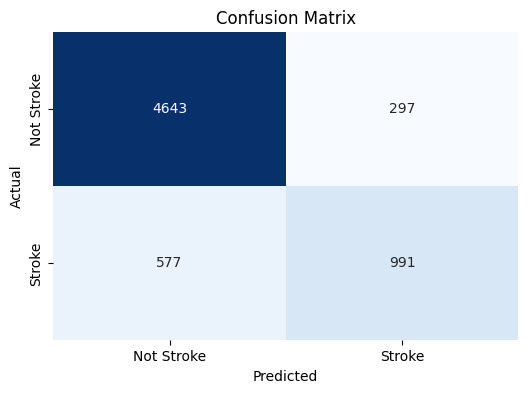


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4940
      Stroke       0.77      0.63      0.69      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.80      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.9205706358960589


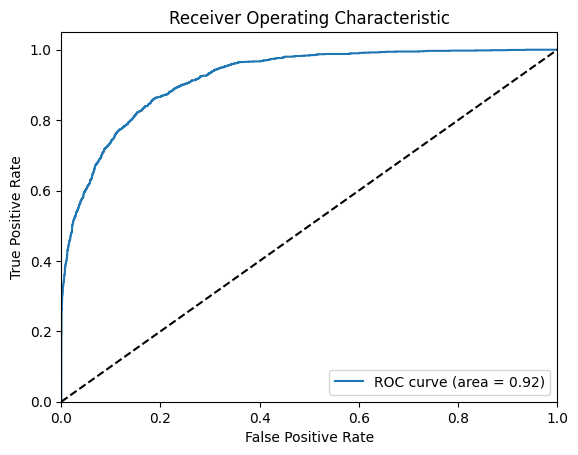

PR AUC: 0.8187505624154963


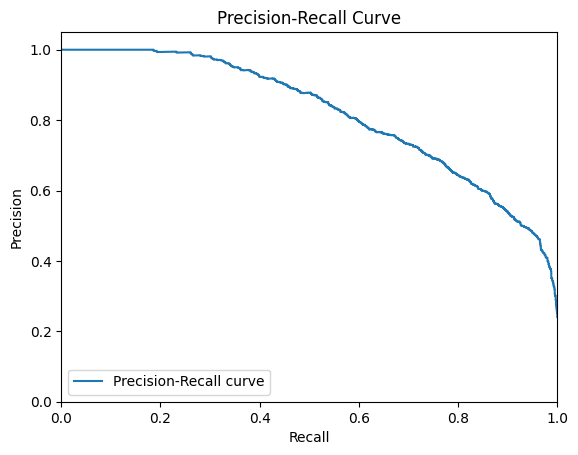

100%|██████████| 13/13 [06:11<00:00, 28.59s/it]


In [44]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [08:44:56] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4308  632]
 [ 368 1200]]


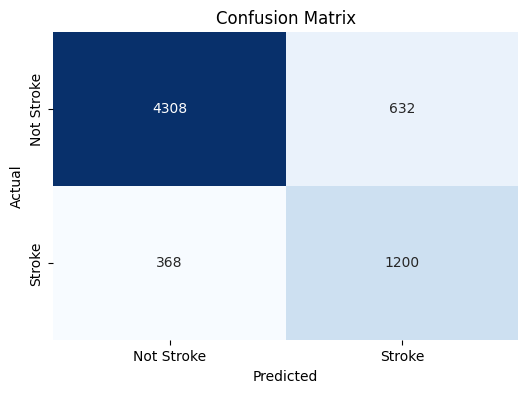


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.92      0.87      0.90      4940
      Stroke       0.66      0.77      0.71      1568

    accuracy                           0.85      6508
   macro avg       0.79      0.82      0.80      6508
weighted avg       0.86      0.85      0.85      6508

ROC-AUC: 0.9083721494670742


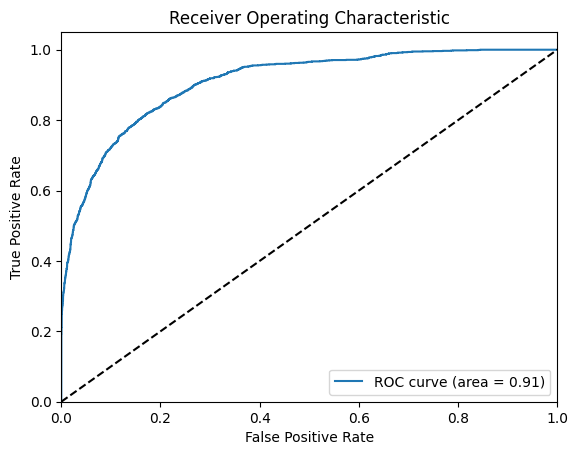

PR AUC: 0.8011619846196872


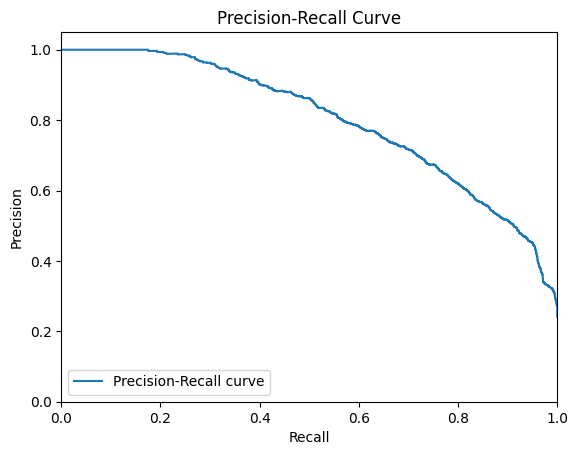

In [45]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [08:45:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4609  331]
 [ 571  997]]


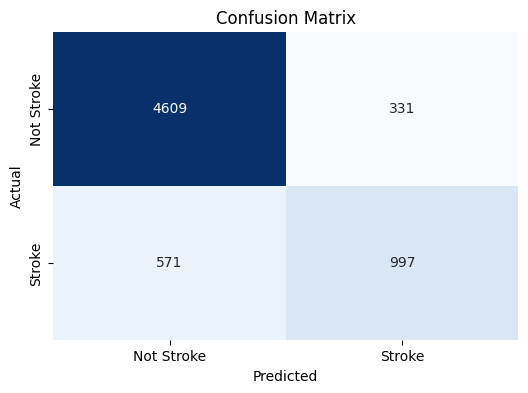


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.93      0.91      4940
      Stroke       0.75      0.64      0.69      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.78      0.80      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.9150809716599191


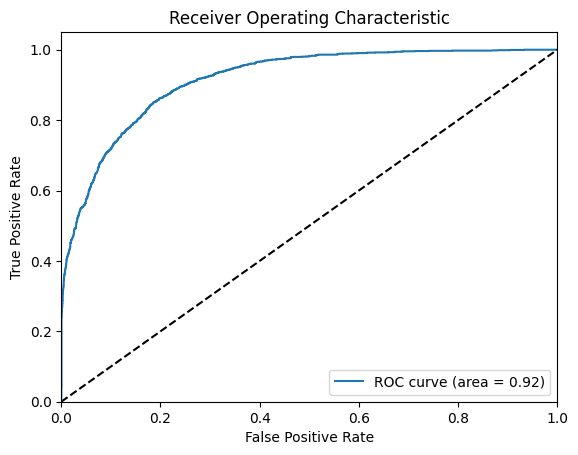

PR AUC: 0.8046647551906676


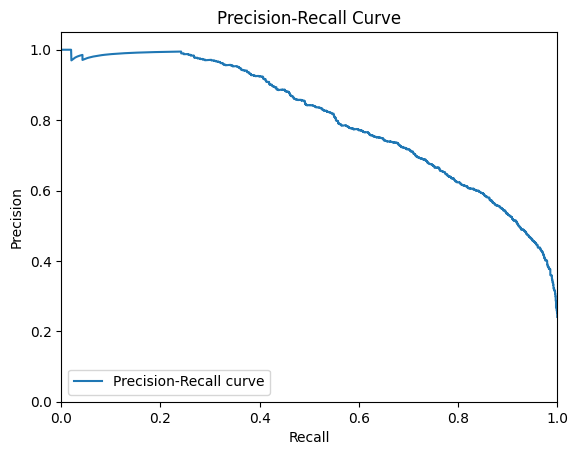

In [46]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),

        
    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [47]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Voting Classifier,0.933651,0.846343,0.814420,0.655022,0.938447,0.765306,0.872046,0.705882,0.935288,0.818685,0.908372,0.801162
CatBoost,0.900496,0.867087,0.843697,0.770177,0.720459,0.639031,0.777223,0.698501,0.839048,0.789252,0.921558,0.820600
Hist Gradient Boosting,0.888547,0.867087,0.820220,0.776990,0.688247,0.628827,0.748461,0.695100,0.820184,0.785770,0.919760,0.818220
LightGBM,0.890391,0.865704,0.821241,0.769410,0.696699,0.632015,0.753861,0.693978,0.824283,0.785947,0.920571,0.818751
XGBoost,0.906489,0.863553,0.851309,0.759146,0.741349,0.635204,0.792533,0.691667,0.850126,0.785618,0.918792,0.815517
Stacking Classifier,0.899804,0.861401,0.844591,0.750753,0.715835,0.635842,0.774901,0.688536,0.837014,0.784419,0.915081,0.804665
Gradient Boosting,0.873065,0.860172,0.794755,0.770559,0.637857,0.597577,0.707714,0.673132,0.792787,0.770549,0.914595,0.807453
Random Forest,1.000000,0.854640,1.000000,0.739231,1.000000,0.612883,1.000000,0.670153,1.000000,0.772130,0.898428,0.766749
Logistic Regression,0.849783,0.849109,0.732703,0.733280,0.592728,0.587372,0.655324,0.652266,0.762049,0.759779,0.898943,0.760179
AdaBoost,0.855392,0.849416,0.753591,0.740196,0.594004,0.577806,0.664348,0.648997,0.766179,0.756717,0.899068,0.766634


<Axes: >

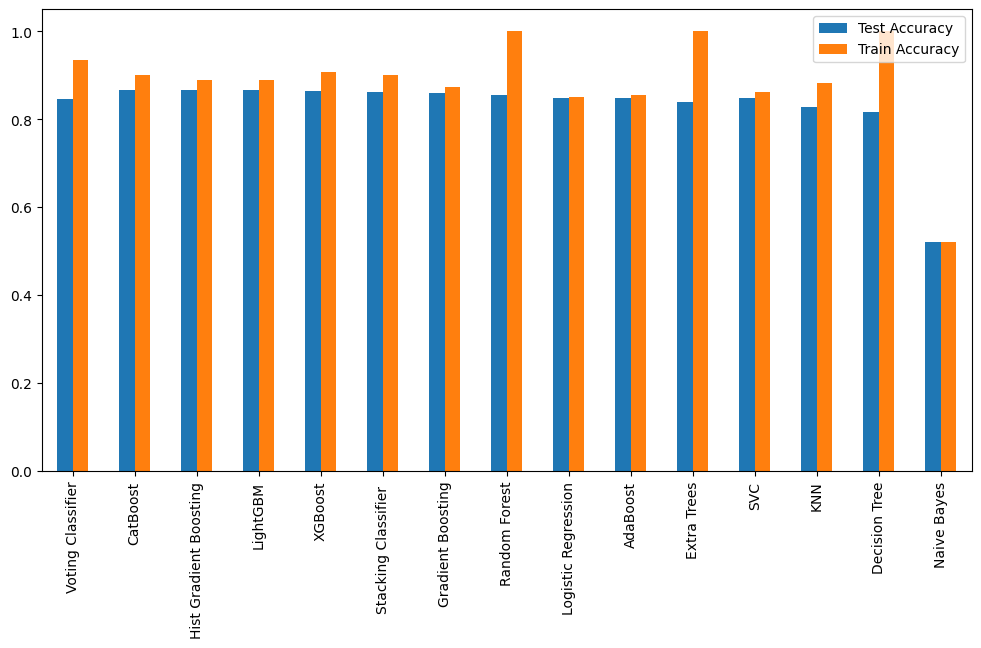

In [48]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

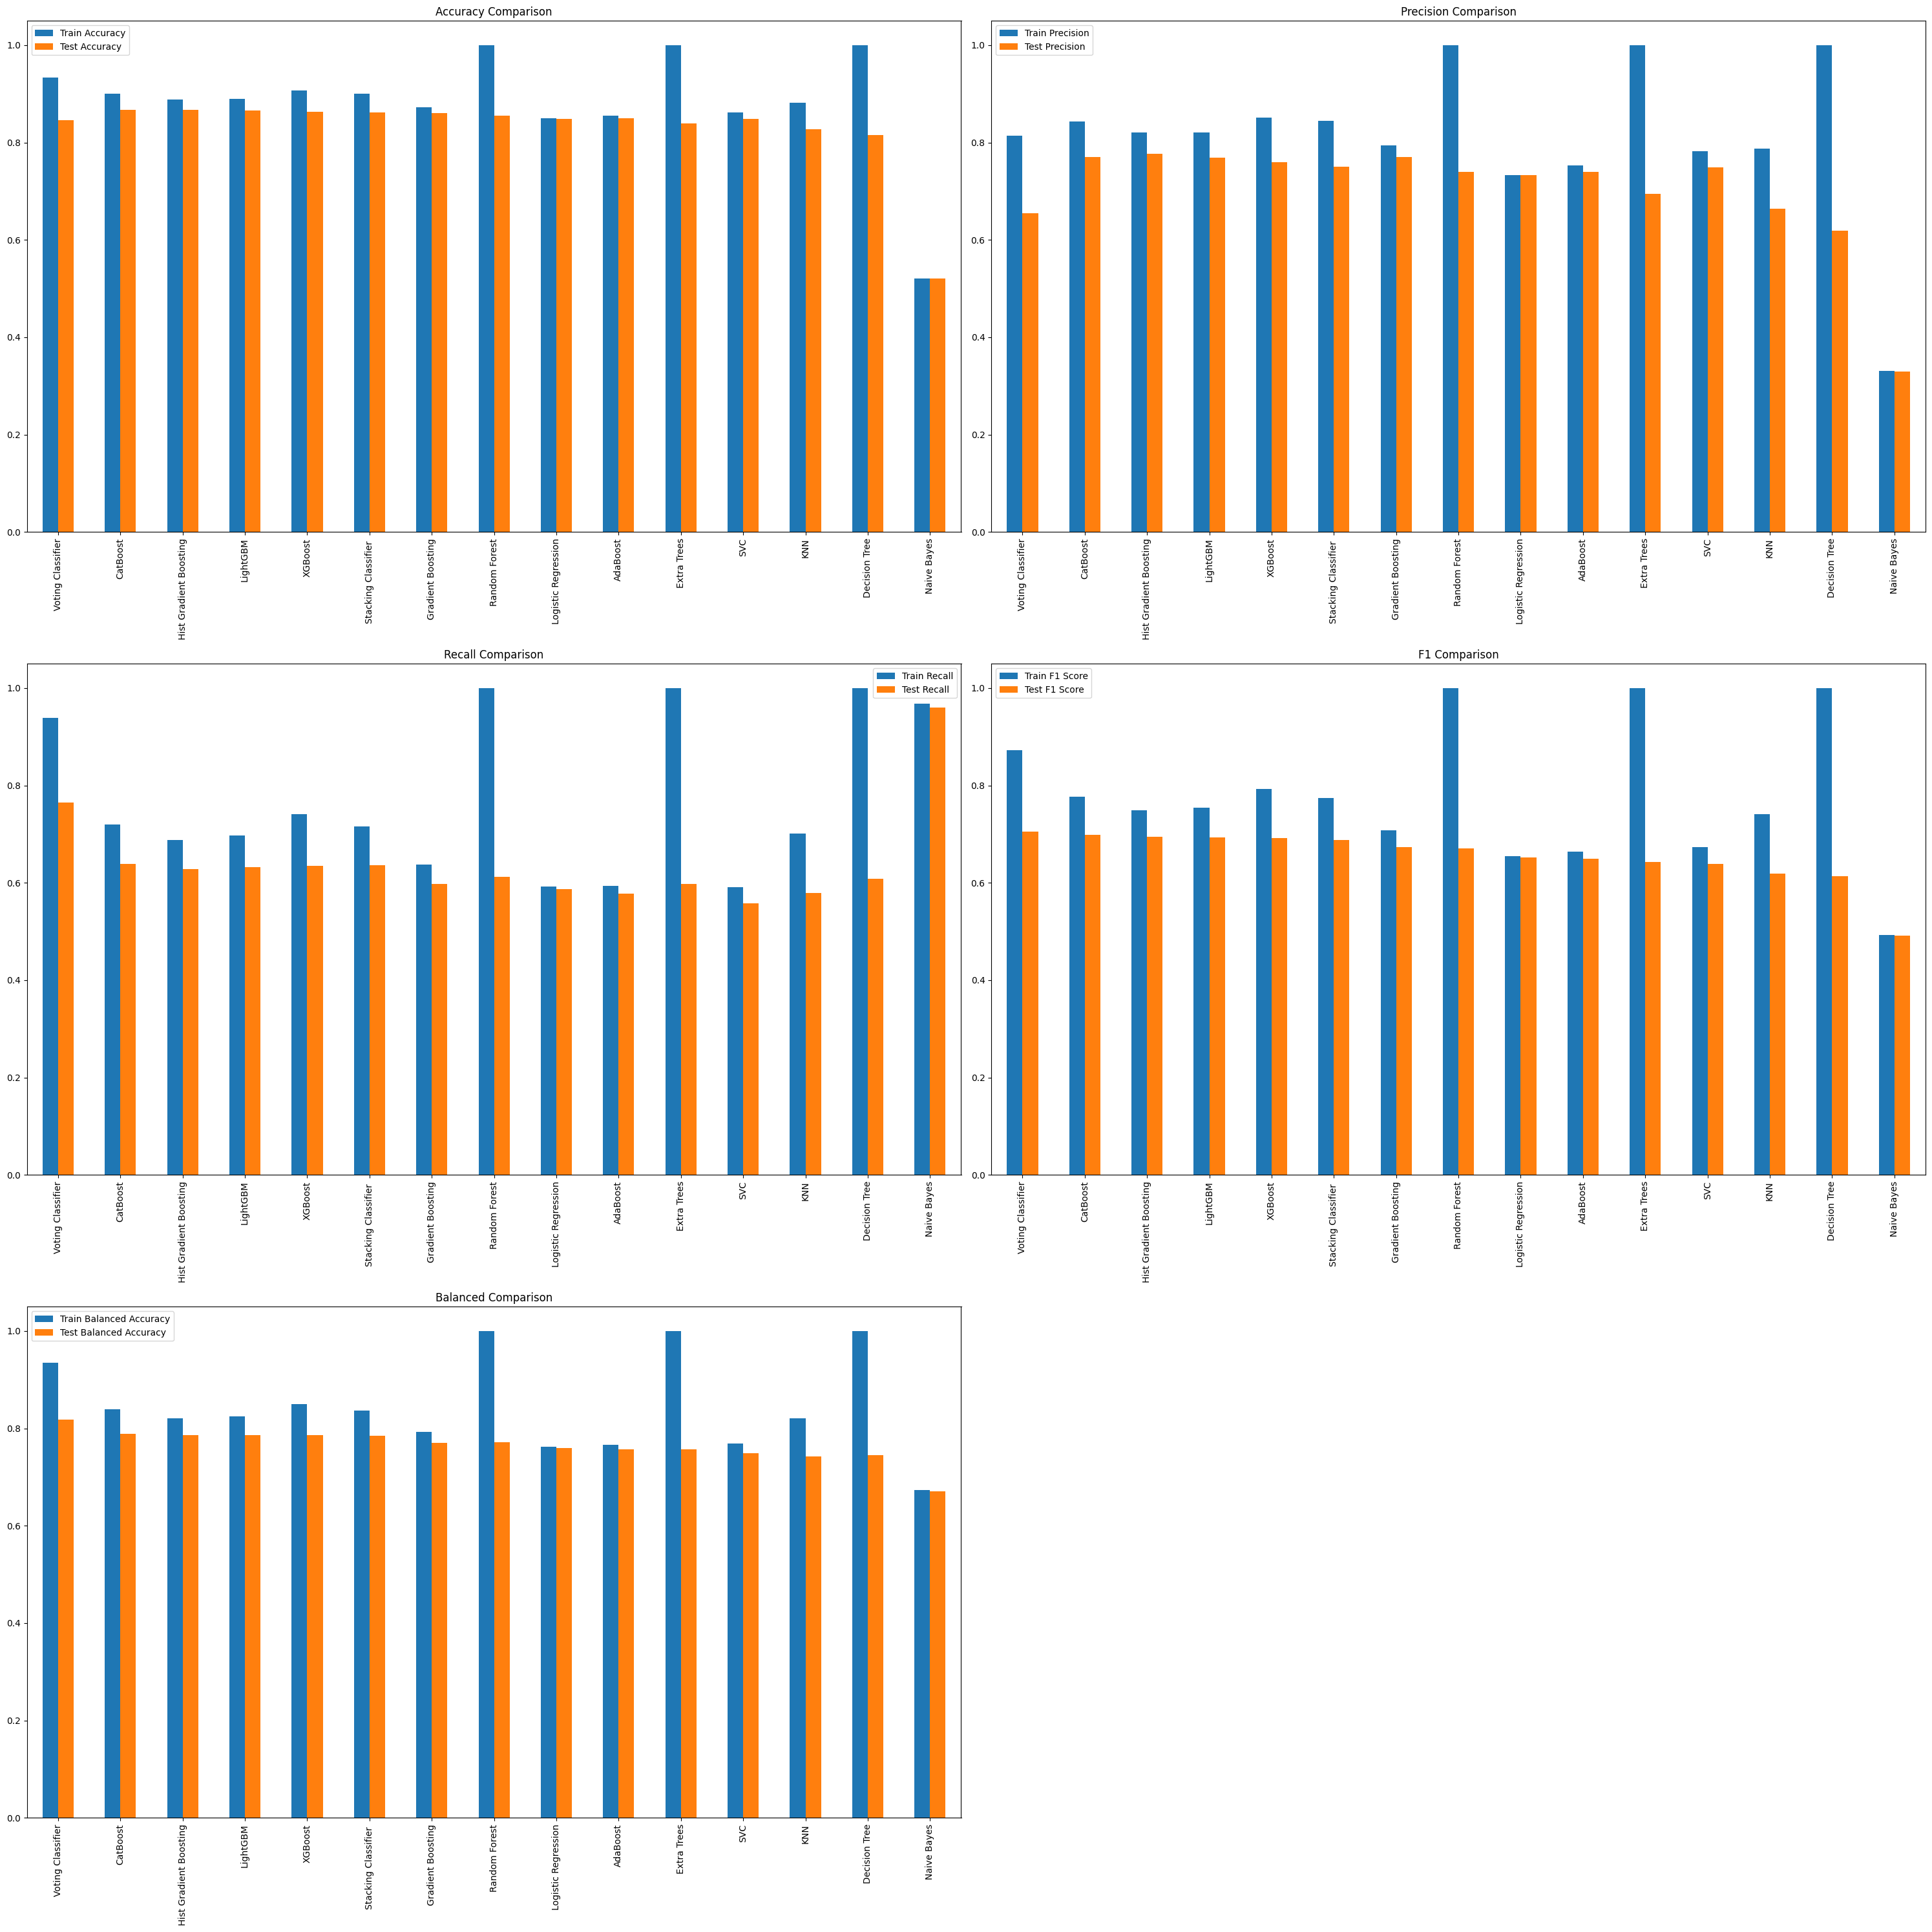

In [49]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)   
    results_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()